# Fase 4 — Avaliação final

Este notebook **só carrega** a configuração e os modelos congelados no `03_modelo.ipynb` e mede tudo no **teste**, que é usado aqui pela primeira e única vez. Nenhuma decisão é tomada. As mesmas funções (`src/avaliacao.py`) também rodam na validação, com os modelos ajustados no treino: isso confere que elas reproduzem o notebook do modelo e dá a comparação validação × teste.

Todas as métricas são as vistas em aula. Intervalos de 95% por bootstrap de usuários (de locais, na saída A), semente 42; diferença cujo intervalo inclui zero é empate.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analises import ic_bootstrap
from src.avaliacao import cenario1, cenario2, cenario3, erros_previsao, pares_roc_consumo, pares_roc_gosto
from src.graficos import COR_EIXO, COR_PRINCIPAL, COR_SECUNDARIA, COR_TEXTO_SECUNDARIO, aplicar_estilo, eixo_br, numero_br, salvar
from src.metricas import comparar, curva_roc_media, intervalo
from src.recomendador import Recomendador

PASTA_PROCESSADOS = Path("data/processed")
PASTA_CONJUNTOS = PASTA_PROCESSADOS / "conjuntos"
NOMES_PESOS = ["alfa", "beta", "gama", "delta"]
PESOS_METODO3 = (0.0, 0.3, 0.0, 0.7)  # escore + popularidade sem informação, escolhidos na validação (03_modelo, cenário 2)
aplicar_estilo()
pd.set_option("display.width", 220, "display.max_colwidth", 70, "display.max_columns", 30)


def inteiro(valor):
    return f"{valor:,}".replace(",", ".")


def com_ic(media, inferior, superior, casas=4):
    return f"{numero_br(media, casas)} [{numero_br(inferior, casas)}; {numero_br(superior, casas)}]"


def texto_ic(comparacao, casas=4):
    marca = " (empate)" if comparacao["empate"] else ""
    return com_ic(comparacao["diferenca"], comparacao["inferior"], comparacao["superior"], casas) + marca


locais = pd.read_parquet(PASTA_PROCESSADOS / "locais.parquet")
treino = pd.read_parquet(PASTA_CONJUNTOS / "treino.parquet")
treino_c3 = pd.read_parquet(PASTA_CONJUNTOS / "treino_c3.parquet")
validacao = pd.read_parquet(PASTA_CONJUNTOS / "validacao.parquet")
treino_total = pd.read_parquet(PASTA_CONJUNTOS / "treino_total.parquet")
treino_total_c3 = pd.read_parquet(PASTA_CONJUNTOS / "treino_total_c3.parquet")
teste = pd.read_parquet(PASTA_CONJUNTOS / "teste.parquet")
locais_novos = pd.read_parquet(PASTA_CONJUNTOS / "locais_novos.parquet")
divisao = json.loads((PASTA_CONJUNTOS / "divisao.json").read_text(encoding="utf-8"))
configuracao = json.loads(Path("modelos/configuracao.json").read_text(encoding="utf-8"))
modelo = joblib.load("modelos/recomendador.joblib")
modelo_c3 = joblib.load("modelos/recomendador_c3.joblib")

assert np.allclose(modelo.pesos, [configuracao["pesos_cenario1"][n] for n in NOMES_PESOS])
assert np.allclose(modelo.pesos_usuario_novo, [configuracao["pesos_cenario2"][n] for n in NOMES_PESOS])
assert np.allclose(modelo_c3.pesos_local_novo, [configuracao["pesos_cenario3"]["alfa"], configuracao["pesos_cenario3"]["gama"]])
for chave in ["percentil", "centro", "local", "tau", "centro_local_novo", "cota_novos"]:
    assert getattr(modelo, chave) == configuracao[chave] == getattr(modelo_c3, chave), chave
assert len(modelo.treino) == len(treino_total) and len(modelo_c3.treino) == len(treino_total_c3)
print(json.dumps(configuracao, ensure_ascii=False))
print(f"Teste: {inteiro(len(teste))} avaliações, de {teste['data'].min():%d/%m/%Y} a {teste['data'].max():%d/%m/%Y}; treino total: {inteiro(len(treino_total))}")


def modelo_da_validacao(treino_ajuste):
    return Recomendador(
        pesos=modelo.pesos, percentil=modelo.percentil, centro=modelo.centro, local=modelo.local, tau=modelo.tau,
        opcoes_vetor=modelo.opcoes_vetor, pesos_usuario_novo=modelo.pesos_usuario_novo, pesos_local_novo=modelo.pesos_local_novo,
        centro_local_novo=modelo.centro_local_novo, cota_novos=modelo.cota_novos,
    ).ajustar(treino_ajuste, locais)


modelo_validacao = modelo_da_validacao(treino)
modelo_validacao_c3 = modelo_da_validacao(treino_c3)
abertos = set(locais.loc[~(locais["fechado_perm"] | locais["fechado_temp"]), "gmap_id"])


def novos_do(conjunto):
    filtro = locais_novos["conjunto"] == conjunto
    return {origem: [g for g in locais_novos.loc[filtro & (locais_novos["origem"] == origem), "gmap_id"] if g in abertos] for origem in ["natural", "simulado"]}


novos_teste, novos_validacao = novos_do("teste"), novos_do("validacao")
print(f"Locais novos abertos no teste: {len(novos_teste['natural'])} naturais e {len(novos_teste['simulado'])} simulados")

{"vetor": {"peso_categorias": 1.0, "peso_atributos": 1.0, "incluir_derivados": false, "incluir_preco": false}, "percentil": 25, "local": "distancia", "tau": 200, "centro": "usuario", "centro_local_novo": "fixo", "pesos_cenario1": {"alfa": 0.1, "beta": 0.2, "gama": 0.5, "delta": 0.2}, "pesos_cenario2": {"alfa": 0.05, "beta": 0.19, "gama": 0.475, "delta": 0.285}, "pesos_cenario3": {"alfa": 0.5, "gama": 0.5}, "cota_novos": 1, "categorias_usuario_novo": "peso", "regularizacao_vies": 10, "criterio": "entre as combinações com conversão@10 de pelo menos 95% da melhor, a de maior AUC de gosto (cenários 1 e 2) ou de consumo (cenário 3)"}
Teste: 85.925 avaliações, de 31/03/2020 a 04/09/2021; treino total: 343.697


Locais novos abertos no teste: 100 naturais e 100 simulados


## Métricas

| Métrica da aula | Papel |
|---|---|
| Taxa de conversão@10 | Principal nos cenários 1 e 2: fração da lista avaliada com nota 4 ou maior |
| Curva ROC: AUC de gosto | Principal nos cenários 1 e 2: notas 4 ou 5 × 3 ou menos, entre os locais avaliados |
| Taxa de conversão, versão literal (consumo@10) | Reportada: fração da lista avaliada com qualquer nota |
| Curva ROC: AUC de consumo | Principal no cenário 3: convertidos × demais candidatos |
| Correlação de rankings (Spearman, tau-b de Kendall) | Confirmação da AUC de gosto |
| MAE, MSE, RMSE | Só para a nota prevista |
| Cobertura do catálogo, dos usuários e dos itens | Proteção contra listas repetidas; decisiva nos cenários 2 e 3 |
| Novidade, serendipidade, diversidade | Acompanhamento (definições da literatura geral) |

## Cenário 1: usuário antigo

Usuários antigos no protocolo: 5.663; candidatos: 1.525; com AUC de gosto: 1.674


,conversão@10,AUC de gosto,consumo@10,conversão@10 − modelo,AUC de gosto − modelo,cobertura do catálogo
modelo,"0,0520 [0,0498; 0,0542]","0,5542 [0,5372; 0,5708]","0,0582 [0,0559; 0,0606]",,,"46,1%"
aleatório,"0,0020 [0,0016; 0,0024]","0,4967 [0,4787; 0,5145]","0,0024 [0,0020; 0,0028]","-0,0500 [-0,0522; -0,0478]","-0,0575 [-0,0825; -0,0327]","100,0%"
popularidade,"0,0144 [0,0134; 0,0155]","0,4584 [0,4416; 0,4753]","0,0162 [0,0152; 0,0173]","-0,0376 [-0,0396; -0,0356]","-0,0957 [-0,1151; -0,0762]","1,4%"
só escore,"0,0028 [0,0024; 0,0033]","0,6943 [0,6781; 0,7098]","0,0030 [0,0026; 0,0035]","-0,0492 [-0,0514; -0,0471]","0,1401 [0,1216; 0,1590]","1,0%"
só local,"0,0298 [0,0282; 0,0314]","0,4876 [0,4703; 0,5054]","0,0352 [0,0333; 0,0370]","-0,0222 [-0,0243; -0,0201]","-0,0665 [-0,0846; -0,0478]","95,7%"
popularidade + local,"0,0532 [0,0510; 0,0556]","0,4516 [0,4349; 0,4692]","0,0644 [0,0620; 0,0671]","0,0013 [-0,0002; 0,0028] (empate)","-0,1026 [-0,1164; -0,0883]","33,2%"
sem conteúdo,"0,0525 [0,0503; 0,0547]","0,5488 [0,5313; 0,5657]","0,0590 [0,0567; 0,0614]","0,0005 [-0,0003; 0,0013] (empate)","-0,0053 [-0,0121; 0,0012] (empate)","41,6%"
vizinhos por item,"0,0599 [0,0575; 0,0623]","0,4477 [0,4306; 0,4648]","0,0743 [0,0715; 0,0772]","0,0079 [0,0058; 0,0101]","-0,1065 [-0,1243; -0,0892]","60,2%"
"vizinhos por item, combinado","0,0651 [0,0626; 0,0676]","0,4887 [0,4717; 0,5060]","0,0778 [0,0750; 0,0806]","0,0131 [0,0114; 0,0148]","-0,0654 [-0,0788; -0,0522]","52,9%"
PageRank personalizado,"0,0637 [0,0611; 0,0661]","0,4493 [0,4315; 0,4673]","0,0772 [0,0744; 0,0800]","0,0117 [0,0100; 0,0134]","-0,1048 [-0,1206; -0,0890]","48,5%"


,conversao,consumo,auc_gosto,auc_consumo,spearman,kendall,novidade,serendipidade,diversidade,cobertura_catalogo,cobertura_usuarios,cobertura_itens
modelo,0.0520,0.0582,0.5542,0.9114,0.0721,0.0619,9.1369,0.0157,0.6912,0.4610,1.0,1.0
aleatório,0.0020,0.0024,0.4967,0.5071,-0.0014,-0.0004,11.7251,0.0018,0.7626,1.0000,1.0,1.0
popularidade,0.0144,0.0162,0.4584,0.7116,-0.0635,-0.0538,7.8179,0.0030,0.6743,0.0138,1.0,1.0
só escore,0.0028,0.0030,0.6943,0.5321,0.2976,0.2605,10.3872,0.0025,0.7809,0.0098,1.0,1.0
só local,0.0298,0.0352,0.4876,0.8862,-0.0148,-0.0111,11.4012,0.0206,0.7473,0.9574,1.0,1.0
popularidade + local,0.0532,0.0644,0.4516,0.9108,-0.0790,-0.0687,8.7020,0.0000,0.6760,0.3318,1.0,1.0
sem conteúdo,0.0525,0.0590,0.5488,0.9117,0.0594,0.0516,9.0943,0.0144,0.6957,0.4157,1.0,1.0
vizinhos por item,0.0599,0.0743,0.4477,0.9081,-0.0867,-0.0749,9.4578,0.0303,0.6403,0.6020,1.0,1.0
"vizinhos por item, combinado",0.0651,0.0778,0.4887,0.9162,-0.0322,-0.0265,9.2331,0.0259,0.6697,0.5292,1.0,1.0
PageRank personalizado,0.0637,0.0772,0.4493,0.9078,-0.0812,-0.0705,8.9634,0.0186,0.6684,0.4852,1.0,1.0


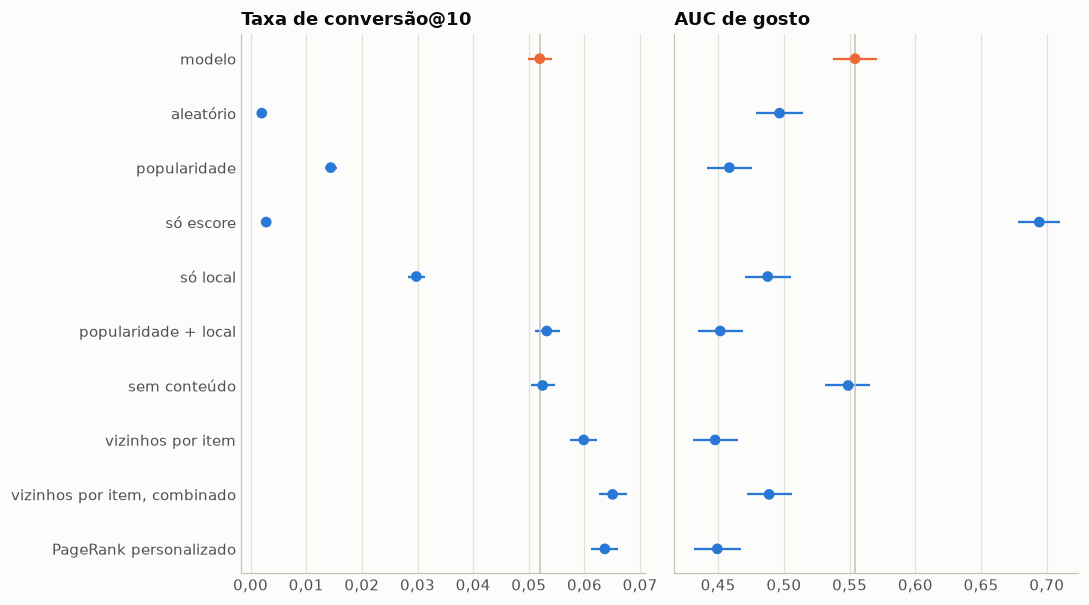

In [2]:
def ordem_de(resultados):
    return list(resultados)


def tabela_com_ic(resultados, base, metricas):
    linhas = {}
    for nome, resultado in resultados.items():
        linha = {}
        for metrica, rotulo in metricas:
            linha[rotulo] = com_ic(*intervalo(resultado, metrica))
        for metrica, rotulo in metricas[:2]:
            linha[f"{rotulo} − {base}"] = "" if nome == base else texto_ic(comparar(resultado, resultados[base], metrica))
        linha["cobertura do catálogo"] = f"{numero_br(100 * resultado.cobertura_catalogo, 1)}%"
        linhas[nome] = linha
    return pd.DataFrame(linhas).T


def grafico_intervalos(resultados, metricas, nome_arquivo, base):
    nomes = list(resultados)[::-1]
    figura, eixos = plt.subplots(1, len(metricas), figsize=(5 * len(metricas), 0.42 * len(nomes) + 1.4), sharey=True)
    for eixo, (metrica, titulo) in zip(np.atleast_1d(eixos), metricas):
        medias, inferiores, superiores = (np.array(v) for v in zip(*(intervalo(resultados[nome], metrica) for nome in nomes)))
        cores = [COR_SECUNDARIA if nome == base else COR_PRINCIPAL for nome in nomes]
        eixo.errorbar(medias, range(len(nomes)), xerr=[medias - inferiores, superiores - medias], fmt="none", ecolor=cores, elinewidth=1.5)
        eixo.scatter(medias, range(len(nomes)), color=cores, s=36, zorder=3)
        eixo.axvline(medias[nomes.index(base)], color=COR_EIXO, linewidth=1)
        eixo.set_title(titulo)
        eixo.grid(axis="y", visible=False)
        eixo_br(eixo.xaxis, 2)
    np.atleast_1d(eixos)[0].set_yticks(range(len(nomes)), nomes)
    figura.tight_layout()
    salvar(figura, nome_arquivo)
    plt.show()


protocolo_c1, modelos_c1, resultados_c1 = cenario1(modelo, treino_total, teste, locais)
print(f"Usuários antigos no protocolo: {inteiro(len(protocolo_c1.usuarios))}; candidatos: {inteiro(len(protocolo_c1.candidatos))}; "
      f"com AUC de gosto: {inteiro(resultados_c1['modelo'].por_usuario['auc_gosto'].notna().sum())}")
metricas_principais = [("conversao", "conversão@10"), ("auc_gosto", "AUC de gosto"), ("consumo", "consumo@10")]
display(tabela_com_ic(resultados_c1, "modelo", metricas_principais))
colunas_c1 = ["conversao", "consumo", "auc_gosto", "auc_consumo", "spearman", "kendall", "novidade", "serendipidade", "diversidade", "cobertura_catalogo", "cobertura_usuarios", "cobertura_itens"]
display(pd.DataFrame({nome: resultado.resumo()[colunas_c1] for nome, resultado in resultados_c1.items()}).T.round(4))
grafico_intervalos(resultados_c1, [("conversao", "Taxa de conversão@10"), ("auc_gosto", "AUC de gosto")], "40_cenario1", "modelo")

In [3]:
_, _, sensibilidade_c1 = cenario1(modelo, treino_total, teste, locais, segmentos=("antigo", "intermediario"), referencias=False, completo=False)
selecionados = {nome: sensibilidade_c1[nome] for nome in ["modelo", "popularidade + local", "sem conteúdo", "aleatório"]}
print(f"Sensibilidade: usuários com 1 ou mais avaliações no treino ({inteiro(len(selecionados['modelo'].por_usuario))} usuários)")
display(tabela_com_ic(selecionados, "modelo", metricas_principais[:2]))

Sensibilidade: usuários com 1 ou mais avaliações no treino (9.949 usuários)


,conversão@10,AUC de gosto,conversão@10 − modelo,AUC de gosto − modelo,cobertura do catálogo
modelo,"0,0438 [0,0423; 0,0454]","0,5566 [0,5423; 0,5706]",,,"50,2%"
popularidade + local,"0,0445 [0,0430; 0,0461]","0,4608 [0,4469; 0,4747]","0,0006 [-0,0004; 0,0016] (empate)","-0,0958 [-0,1082; -0,0843]","36,0%"
sem conteúdo,"0,0443 [0,0428; 0,0458]","0,5525 [0,5384; 0,5666]","0,0004 [-0,0001; 0,0010] (empate)","-0,0041 [-0,0096; 0,0015] (empate)","45,1%"
aleatório,"0,0019 [0,0016; 0,0022]","0,5045 [0,4897; 0,5192]","-0,0420 [-0,0435; -0,0405]","-0,0521 [-0,0721; -0,0326]","100,0%"


**Leitura do cenário 1 (teste):**

- **O modelo** converte 0,0520 (IC 95% de 0,0498 a 0,0542) com AUC de gosto de 0,5542 (IC 95% de 0,5372 a 0,5708), em 5.663 usuários antigos; a AUC de gosto vale para 1.674 deles. A cobertura do catálogo é de 46,1%.
- **Popularidade + local**, a lista óbvia, empata na conversão (+0,0013, IC 95% de −0,0002 a 0,0028), mas tem AUC de gosto de 0,4516, abaixo do acaso, e cobre 33,2% do catálogo. **Sem conteúdo** empata nas duas métricas, como na validação.
- **As técnicas colaborativas convertem mais:** vizinhos por item 0,0599 (+0,0079), PageRank 0,0637 (+0,0117) e o combinado 0,0651 (+0,0131, IC 95% de 0,0114 a 0,0148), 25% acima do modelo. Todas ficam abaixo do acaso na AUC de gosto (0,4477 a 0,4887), como a popularidade.
- **Só o escore** tem a maior AUC de gosto (0,6943) e quase não converte (0,0028): o sinal de gosto vem da qualidade do local.
- **Sensibilidade** (9.949 usuários com 1 ou mais avaliações no treino): o modelo converte 0,0438 e empata na conversão com popularidade + local e com sem conteúdo; na AUC de gosto, fica 0,0958 acima de popularidade + local.

## Cenário 2: usuário novo

O mesmo protocolo da validação: usuários sem avaliações no treino total, com 2 ou mais avaliações no teste; a primeira simula o cadastro.

Usuários no protocolo: 6.783; com AUC de gosto: 1.255


,conversão@10,AUC de gosto,consumo@10,conversão@10 − 5. modelo: + categorias com peso,AUC de gosto − 5. modelo: + categorias com peso,cobertura do catálogo
1. popularidade,"0,0097 [0,0089; 0,0105]","0,4916 [0,4691; 0,5139]","0,0106 [0,0098; 0,0114]","-0,0356 [-0,0373; -0,0338]","-0,0682 [-0,0915; -0,0465]","0,7%"
2. escore,"0,0020 [0,0017; 0,0024]","0,6739 [0,6536; 0,6940]","0,0021 [0,0018; 0,0024]","-0,0432 [-0,0451; -0,0414]","0,1141 [0,0860; 0,1416]","0,7%"
3. escore + popularidade,"0,0097 [0,0089; 0,0105]","0,5591 [0,5368; 0,5795]","0,0103 [0,0095; 0,0112]","-0,0356 [-0,0373; -0,0338]","-0,0007 [-0,0198; 0,0181] (empate)","0,7%"
4. local + escore + popularidade,"0,0450 [0,0433; 0,0469]","0,5623 [0,5402; 0,5834]","0,0496 [0,0477; 0,0516]","-0,0002 [-0,0005; 0,0002] (empate)","0,0025 [-0,0024; 0,0077] (empate)","27,0%"
5. modelo: + categorias com peso,"0,0452 [0,0435; 0,0471]","0,5598 [0,5376; 0,5806]","0,0499 [0,0479; 0,0518]",,,"30,6%"
5. + categorias como filtro,"0,0232 [0,0218; 0,0246]","0,4983 [0,4763; 0,5201]","0,0269 [0,0254; 0,0285]","-0,0221 [-0,0238; -0,0204]","-0,0615 [-0,0777; -0,0446]","81,6%"
"6. + local de exemplo, mesmo peso","0,0453 [0,0436; 0,0472]","0,5564 [0,5340; 0,5776]","0,0499 [0,0480; 0,0519]","0,0001 [-0,0003; 0,0006] (empate)","-0,0034 [-0,0087; 0,0015] (empate)","30,4%"


,conversao,consumo,auc_gosto,auc_consumo,novidade,serendipidade,diversidade,cobertura_catalogo,cobertura_usuarios
1. popularidade,0.0097,0.0106,0.4916,0.7423,7.8022,0.0026,0.6623,0.0072,1.0
2. escore,0.0020,0.0021,0.6739,0.5611,10.3790,0.0015,0.7816,0.0072,1.0
3. escore + popularidade,0.0097,0.0103,0.5591,0.7492,7.8693,0.0024,0.6625,0.0072,1.0
4. local + escore + popularidade,0.0450,0.0496,0.5623,0.8966,9.1194,0.0091,0.7105,0.2702,1.0
5. modelo: + categorias com peso,0.0452,0.0499,0.5598,0.8971,9.1164,0.0091,0.7103,0.3056,1.0
5. + categorias como filtro,0.0232,0.0269,0.4983,0.8377,10.0599,0.0145,0.5365,0.8164,1.0
"6. + local de exemplo, mesmo peso",0.0453,0.0499,0.5564,0.8975,9.1285,0.0094,0.7056,0.3043,1.0


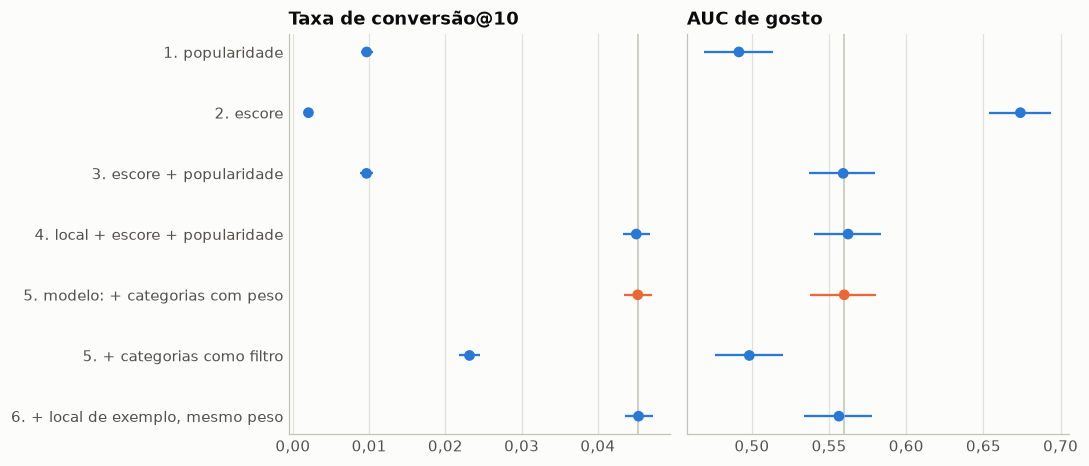

In [4]:
protocolo_c2, modelos_c2, resultados_c2 = cenario2(modelo, treino_total, teste, locais, PESOS_METODO3)
base_c2 = "5. modelo: + categorias com peso"
print(f"Usuários no protocolo: {inteiro(len(protocolo_c2.usuarios))}; com AUC de gosto: {inteiro(resultados_c2[base_c2].por_usuario['auc_gosto'].notna().sum())}")
display(tabela_com_ic(resultados_c2, base_c2, metricas_principais))
colunas_c2 = ["conversao", "consumo", "auc_gosto", "auc_consumo", "novidade", "serendipidade", "diversidade", "cobertura_catalogo", "cobertura_usuarios"]
display(pd.DataFrame({nome: resultado.resumo()[colunas_c2] for nome, resultado in resultados_c2.items()}).T.round(4))
grafico_intervalos(resultados_c2, [("conversao", "Taxa de conversão@10"), ("auc_gosto", "AUC de gosto")], "41_cenario2", base_c2)

**Leitura do cenário 2 (teste):** em 6.783 usuários novos (1.255 com AUC de gosto), o modelo converte 0,0452 (IC 95% de 0,0435 a 0,0471) com AUC de gosto de 0,5598, quase cinco vezes a conversão da popularidade global (0,0097). Como na validação, a categoria declarada com peso empata com o método 4 (só a cidade) nas duas métricas e amplia o catálogo de 27,0% para 30,6%; como filtro, derruba a conversão para 0,0232 e a AUC de gosto em 0,0615. O local de exemplo também empata. A cobertura de usuários é de 100% em todos os métodos.

## Cenário 3: local novo para usuário antigo

Modelo ajustado no treino total do cenário 3, sem os 100 locais simulados do teste. Os locais **naturais** são o resultado principal; os **simulados**, à parte.

Locais novos naturais: 100; usuários com conversão: 729; avaliações deles no treino do cenário 3: 0


,AUC de consumo,conversão@10,AUC de consumo − só local,conversão − só local,cobertura dos itens
aleatório,"0,4779 [0,4563; 0,4983]","0,0111 [0,0089; 0,0134]","-0,4394 [-0,4630; -0,4169]","-0,0770 [-0,0818; -0,0726]","100,0%"
só local,"0,9173 [0,9072; 0,9269]","0,0881 [0,0844; 0,0920]",,,"100,0%"
só conteúdo,"0,5402 [0,5194; 0,5599]","0,0155 [0,0130; 0,0182]","-0,3772 [-0,3996; -0,3541]","-0,0726 [-0,0772; -0,0680]","100,0%"
modelo,"0,9209 [0,9102; 0,9303]","0,0867 [0,0827; 0,0908]","0,0036 [-0,0008; 0,0076] (empate)","-0,0014 [-0,0044; 0,0014] (empate)","100,0%"


Saída A (AUC por local): modelo 0,8938 [0,8704; 0,9165]; só local 0,8882 [0,8627; 0,9116]; aleatório 0,5025 [0,4662; 0,5382]; modelo − só local 0,0056 [-0,0016; 0,0127]; locais com AUC: 88


,usuarios,com conversão em local novo,posição mediana do convertido,convertidos no top-10 (%),"listas com local novo (%), sem cota","listas com local novo convertido, sem cota","novos em alguma lista, sem cota","conversão@10, sem cota","listas com local novo (%), com cota","listas com local novo convertido, com cota","novos em alguma lista, com cota","conversão@10, com cota",novos
naturais,5488.0,729.0,72.0,3.1439,3.6808,21.0,42.0,0.0496,100.0,126.0,95.0,0.0482,100.0


Cota: conversão@10 com − sem -0,0014 [-0,0020; -0,0008]
Vizinhos por item e PageRank pontuam 0% destes locais, pois eles têm 0 avaliações no treino do cenário 3.
Locais novos simulados: 100; usuários com conversão: 1.107; avaliações deles no treino do cenário 3: 0


,AUC de consumo,conversão@10,AUC de consumo − só local,conversão − só local,cobertura dos itens
aleatório,"0,5084 [0,4922; 0,5247]","0,0131 [0,0110; 0,0151]","-0,3686 [-0,3878; -0,3492]","-0,0640 [-0,0681; -0,0598]","100,0%"
só local,"0,8770 [0,8659; 0,8875]","0,0771 [0,0734; 0,0808]",,,"100,0%"
só conteúdo,"0,5799 [0,5639; 0,5950]","0,0164 [0,0143; 0,0187]","-0,2971 [-0,3156; -0,2785]","-0,0606 [-0,0650; -0,0564]","100,0%"
modelo,"0,8814 [0,8714; 0,8915]","0,0793 [0,0758; 0,0829]","0,0044 [0,0002; 0,0084]","0,0023 [-0,0000; 0,0045] (empate)","100,0%"


Saída A (AUC por local): modelo 0,8954 [0,8814; 0,9086]; só local 0,8843 [0,8696; 0,8982]; aleatório 0,4971 [0,4740; 0,5210]; modelo − só local 0,0112 [0,0052; 0,0167]; locais com AUC: 91


,usuarios,com conversão em local novo,posição mediana do convertido,convertidos no top-10 (%),"listas com local novo (%), sem cota","listas com local novo convertido, sem cota","novos em alguma lista, sem cota","conversão@10, sem cota","listas com local novo (%), com cota","listas com local novo convertido, com cota","novos em alguma lista, com cota","conversão@10, com cota",novos
simulados,5474.0,1107.0,85.0,1.283,3.4892,15.0,39.0,0.0497,100.0,151.0,87.0,0.0488,100.0


Cota: conversão@10 com − sem -0,0009 [-0,0015; -0,0003]
Vizinhos por item e PageRank pontuam 0% destes locais, pois eles têm 0 avaliações no treino do cenário 3.


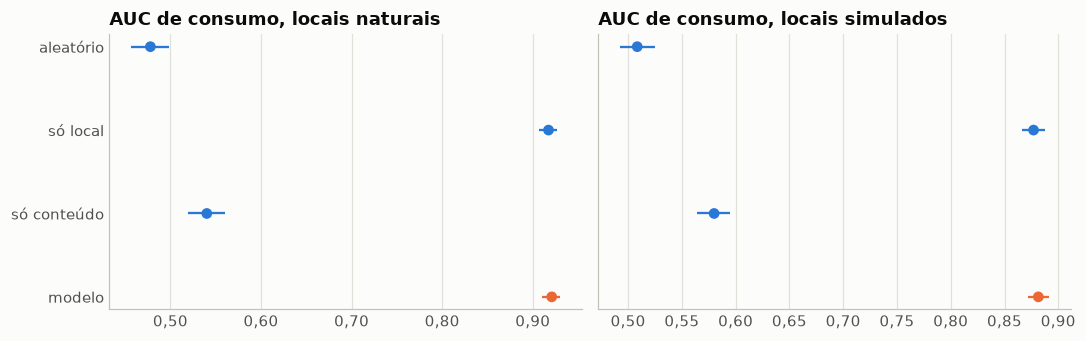

In [5]:
PLURAL = {"natural": "naturais", "simulado": "simulados"}
resultados_c3 = cenario3(modelo_c3, treino_total_c3, teste, locais, novos_teste)
for origem, resultado in resultados_c3.items():
    protocolo = resultado["protocolo"]
    print(f"Locais novos {PLURAL[origem]}: {len(protocolo.candidatos)}; usuários com conversão: {inteiro(len(protocolo.usuarios))}; "
          f"avaliações deles no treino do cenário 3: {resultado['avaliacoes_no_treino']}")
    ordenar = resultado["ordenar"]
    linhas = {}
    for nome, avaliado in ordenar.items():
        linhas[nome] = {
            "AUC de consumo": com_ic(*intervalo(avaliado, "auc_consumo")),
            "conversão@10": com_ic(*intervalo(avaliado, "conversao")),
            "AUC de consumo − só local": "" if nome == "só local" else texto_ic(comparar(avaliado, ordenar["só local"], "auc_consumo")),
            "conversão − só local": "" if nome == "só local" else texto_ic(comparar(avaliado, ordenar["só local"], "conversao")),
            "cobertura dos itens": f"{numero_br(100 * avaliado.cobertura_itens, 1)}%",
        }
    display(pd.DataFrame(linhas).T)
    saida_a = resultado["saida_a"]
    validos = ~np.isnan(saida_a["modelo"])
    diferenca = saida_a["modelo"][validos] - saida_a["só local"][validos]
    print("Saída A (AUC por local): " + "; ".join(f"{nome} {com_ic(r['media'], r['inferior'], r['superior'])}" for nome, r in resultado["saida_a_resumo"].items())
          + f"; modelo − só local {com_ic(*ic_bootstrap(diferenca))}; locais com AUC: {int(validos.sum())}")
    display(pd.DataFrame({PLURAL[origem]: {chave: round(valor, 4) if isinstance(valor, float) else valor for chave, valor in resultado["saida_b"].items()}}).T)
    print(f"Cota: conversão@10 com − sem {texto_ic(resultado['cota'])}")
    print("Vizinhos por item e PageRank pontuam 0% destes locais, pois eles têm 0 avaliações no treino do cenário 3.")

figura, eixos = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for eixo, origem in zip(eixos, ["natural", "simulado"]):
    ordenar = resultados_c3[origem]["ordenar"]
    nomes = list(ordenar)[::-1]
    medias, inferiores, superiores = (np.array(v) for v in zip(*(intervalo(ordenar[nome], "auc_consumo") for nome in nomes)))
    cores = [COR_SECUNDARIA if nome == "modelo" else COR_PRINCIPAL for nome in nomes]
    eixo.errorbar(medias, range(len(nomes)), xerr=[medias - inferiores, superiores - medias], fmt="none", ecolor=cores, elinewidth=1.5)
    eixo.scatter(medias, range(len(nomes)), color=cores, s=36, zorder=3)
    eixo.set_title(f"AUC de consumo, locais {PLURAL[origem]}")
    eixo.grid(axis="y", visible=False)
    eixo_br(eixo.xaxis, 2)
eixos[0].set_yticks(range(len(nomes)), nomes)
figura.tight_layout()
salvar(figura, "42_cenario3")
plt.show()

**Leitura do cenário 3 (teste):**

- **Naturais (resultado principal):** o modelo tem AUC de consumo de 0,9209 contra 0,9173 só com o local: **+0,0036, IC 95% de −0,0008 a 0,0076, empate**. A conversão@10 também empata (−0,0014). Na validação, o conteúdo tinha somado 0,0119; no teste, o ganho não se confirma nos locais novos reais. O conteúdo sozinho cai para 0,5402, pouco acima do acaso. A saída A também empata (0,8938 contra 0,8882, diferença de 0,0056, IC 95% de −0,0016 a 0,0127, em 88 locais).
- **Simulados:** o conteúdo ajuda pouco, mas fora do empate: +0,0044 de AUC de consumo (IC 95% de 0,0002 a 0,0084) e +0,0112 na saída A (IC 95% de 0,0052 a 0,0167). Os simulados têm metadados mais ricos que os novos reais, o que pode explicar a diferença.
- **Saída B:** na lista do cenário 1, o local novo natural que a pessoa avaliou bem fica em 72º, em mediana, e só 3,1% chegam ao top-10; 3,7% das listas têm algum local novo.
- **Cota:** com 1 local novo garantido, as listas que acertam um local novo natural passam de 21 para 126, e os locais novos listados, de 42 para 95 de 100, ao custo de 0,0014 de conversão@10 (de 0,0496 para 0,0482; IC 95% de −0,0020 a −0,0008). Nos simulados, de 15 para 151 listas, com −0,0009.
- **Cobertura do espaço de itens novos:** o conteúdo pontua 100% dos locais novos; vizinhos por item e PageRank, 0%.

## Curvas ROC

Curvas médias entre usuários: a de **gosto** no cenário 1 (locais avaliados no teste, nota 4 ou maior × 3 ou menor) e a de **consumo** no cenário 3 (locais novos naturais convertidos × demais).

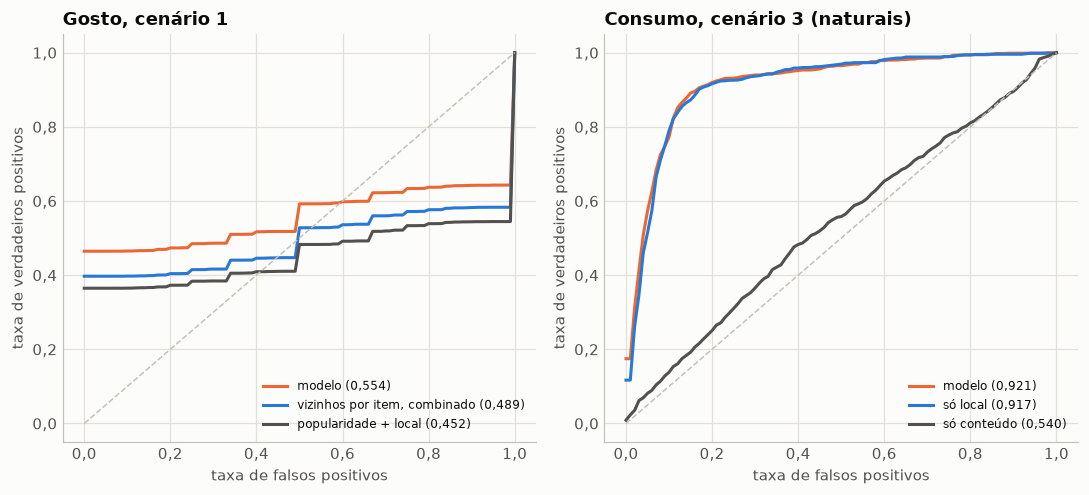

Entre parênteses, a AUC média por usuário; a curva é a média das curvas por usuário.


In [6]:
def curva(protocolo, funcao, tipo):
    pontuacoes = funcao(protocolo.usuarios, protocolo.candidatos)
    pares = pares_roc_gosto(protocolo, pontuacoes) if tipo == "gosto" else pares_roc_consumo(protocolo, pontuacoes)
    return curva_roc_media(pares)


figura, (eixo_gosto, eixo_consumo) = plt.subplots(1, 2, figsize=(10, 4.6))
series_gosto = [("modelo", COR_SECUNDARIA), ("vizinhos por item, combinado", COR_PRINCIPAL), ("popularidade + local", COR_TEXTO_SECUNDARIO)]
for nome, cor in series_gosto:
    x, y = curva(protocolo_c1, modelos_c1[nome], "gosto")
    eixo_gosto.plot(x, y, color=cor, label=f"{nome} ({numero_br(resultados_c1[nome].resumo()['auc_gosto'], 3)})")
protocolo_naturais = resultados_c3["natural"]["protocolo"]
modelos_naturais = resultados_c3["natural"]["ordenar_modelos"]
for nome, cor in [("modelo", COR_SECUNDARIA), ("só local", COR_PRINCIPAL), ("só conteúdo", COR_TEXTO_SECUNDARIO)]:
    x, y = curva(protocolo_naturais, modelos_naturais[nome], "consumo")
    eixo_consumo.plot(x, y, color=cor, label=f"{nome} ({numero_br(resultados_c3['natural']['ordenar'][nome].resumo()['auc_consumo'], 3)})")
for eixo, titulo in [(eixo_gosto, "Gosto, cenário 1"), (eixo_consumo, "Consumo, cenário 3 (naturais)")]:
    eixo.plot([0, 1], [0, 1], color=COR_EIXO, linewidth=1, linestyle="--")
    eixo.set_title(titulo)
    eixo.set_xlabel("taxa de falsos positivos")
    eixo.set_ylabel("taxa de verdadeiros positivos")
    eixo.legend(frameon=False, fontsize=8, loc="lower right")
    eixo_br(eixo.xaxis, 1)
    eixo_br(eixo.yaxis, 1)
figura.tight_layout()
salvar(figura, "43_curvas_roc")
plt.show()
print("Entre parênteses, a AUC média por usuário; a curva é a média das curvas por usuário.")

**Leitura das curvas ROC:** a curva de gosto é feita de degraus porque a maioria dos usuários tem só um ou dois locais bons e um ou dois ruins no teste. Ela começa na fração de usuários em que todos os locais bons ficam acima dos ruins: cerca de 46% no modelo, 40% no combinado e 36% em popularidade + local. Na curva de consumo dos locais novos, o modelo e o só local quase se sobrepõem, como o empate da tabela, e o conteúdo sozinho fica perto da diagonal.

## Previsão de nota

In [7]:
erros_teste, contagem_teste = erros_previsao(modelo, treino_total, teste)
print(f"Avaliações de usuários antigos em locais do treino total: {inteiro(contagem_teste['avaliacoes'])}, de {inteiro(contagem_teste['usuarios'])} usuários")
display(pd.DataFrame({
    nome: {medida: com_ic(linha[medida], linha[f"{medida} inf"], linha[f"{medida} sup"]) for medida in ["MAE", "MSE", "RMSE"]}
    for nome, linha in erros_teste.iterrows()
}).T)
correlacao = {nome: resultados_c1[nome].resumo()[["spearman", "kendall"]] for nome in ["modelo", "sem conteúdo", "popularidade + local", "vizinhos por item, combinado"]}
print("Correlação de rankings entre pontuação e nota (cenário 1):")
display(pd.DataFrame(correlacao).T.round(4))

Avaliações de usuários antigos em locais do treino total: 21.121, de 6.335 usuários


,MAE,MSE,RMSE
média global,"0,8982 [0,8853; 0,9109]","1,2854 [1,2449; 1,3271]","1,1337 [1,1158; 1,1520]"
escore,"0,8524 [0,8403; 0,8649]","1,1755 [1,1382; 1,2143]","1,0842 [1,0668; 1,1019]"
escore + viés,"0,7751 [0,7623; 0,7880]","1,0502 [1,0139; 1,0855]","1,0248 [1,0069; 1,0418]"


Correlação de rankings entre pontuação e nota (cenário 1):


,spearman,kendall
modelo,0.0721,0.0619
sem conteúdo,0.0594,0.0516
popularidade + local,-0.0790,-0.0687
"vizinhos por item, combinado",-0.0322,-0.0265


**Leitura da previsão de nota:** em 21.121 avaliações de 6.335 usuários antigos, o escore + viés tem o menor erro (RMSE de 1,0248, MAE de 0,7751), contra 1,0842 do escore e 1,1337 da média global, a mesma ordem da validação, com erros um pouco maiores. A correlação de rankings do modelo cai para 0,0721 (Spearman), mas segue a maior entre as ordenações comparadas; popularidade + local e o combinado têm correlação negativa.

## Qualidade da lista e exemplos

As medidas de acompanhamento do cenário 1 estão na tabela completa acima. Aqui, dois usuários do protocolo, sorteados com semente 42 entre os que converteram ao menos dois locais no teste: a lista que o sistema mostraria (com a cota de local novo) ao lado do que eles avaliaram depois.

In [8]:
conversoes_por_usuario = (protocolo_c1.notas >= 4).sum(axis=1).A1
sorteados = np.random.default_rng(42).choice(protocolo_c1.usuarios[conversoes_por_usuario >= 2], size=2, replace=False)
nomes_locais = locais.set_index("gmap_id")["name"]
for rotulo, usuario in zip(["Usuário 1", "Usuário 2"], sorteados):
    lista = modelo.recomendar(usuario, n=10)
    no_teste = teste[teste["user_id"] == usuario].set_index("gmap_id")["rating"]
    lista["nota no teste"] = lista["gmap_id"].map(no_teste)
    print(f"{rotulo}: {len(modelo.treino[modelo.treino['user_id'] == usuario])} avaliações no treino total; {len(no_teste)} no teste")
    with pd.option_context("display.max_colwidth", 110):
        display(lista[["nome", "cidade", "categoria_principal", "pontuacao", "novo", "nota no teste", "explicacao"]].round(3))
    fora = no_teste[~no_teste.index.isin(lista["gmap_id"])]
    print("  Avaliados no teste e fora da lista: " + "; ".join(f"{nomes_locais.get(g, g)} ({nota})" for g, nota in fora.items()))

Usuário 1: 31 avaliações no treino total; 6 no teste


,nome,cidade,categoria_principal,pontuacao,novo,nota no teste,explicacao
0,El Jaliciense of Wyoming,Kemmerer,Mexican restaurant,0.703,False,NaN,"Porque você gostou de Costa Vida (nota 5). Em comum com seu perfil: Cadeirões, Refeição no local, Bom para..."
1,Chill Grill,Rock Springs,Hamburger restaurant,0.702,False,NaN,"Porque você gostou de Wendy's (nota 5). Em comum com seu perfil: Hamburgueria, Banheiro acessível, Cadeirões."
2,Sapporo | Japanese Steakhouse,Rock Springs,Japanese steakhouse,0.700,False,NaN,"Porque você gostou de Cavalryman Steakhouse (nota 5). Em comum com seu perfil: Banheiro acessível, Cadeirõ..."
3,Broadway Burger Station,Rock Springs,Hamburger restaurant,0.697,False,NaN,"Porque você gostou de Denny's (nota 5). Em comum com seu perfil: Hamburgueria, Banheiro acessível, Restaur..."
4,Cowboy Cafe,Lyman,Cafe,0.695,False,NaN,"Porque você gostou de Caribou Cafe (nota 5). Em comum com seu perfil: Cadeirões, Refeição no local, Bom pa..."
5,Arctic Circle,Green River,Fast food restaurant,0.694,False,NaN,"Porque você gostou de Arctic Circle (nota 5). Em comum com seu perfil: Drive-thru, Pagamento por aproximaç..."
6,Wendy's,Rock Springs,Fast food restaurant,0.689,False,NaN,"Porque você gostou de Wendy's (nota 5). Em comum com seu perfil: Fast food, Hamburgueria, Drive-thru."
7,Jalisco Mexican Grill,Evanston,Mexican restaurant,0.689,False,NaN,"Porque você gostou de Costa Vida (nota 5). Em comum com seu perfil: Cadeirões, Refeição no local, Bom para..."
8,The Hitching Post,Green River,Restaurant,0.688,False,NaN,"Porque você gostou de Burger King (nota 5). Em comum com seu perfil: Restaurante, Drive-thru, Banheiro ace..."
9,Deja Brew,Rock Springs,Coffee shop,0.641,True,NaN,"Porque você gostou de Jody's Diner (nota 5). Em comum com seu perfil: Bom para crianças, Para viagem, Entr..."


  Avaliados no teste e fora da lista: CLUB 307 (5); Pancho's Méxican Food (5); IHOP (5); Silver Fox Steakhouse (5); Penny's Diner (5); Virginian Restaurant (5)


Usuário 2: 5 avaliações no treino total; 2 no teste


,nome,cidade,categoria_principal,pontuacao,novo,nota no teste,explicacao
0,Santa Fe Southwest Grill,Rock Springs,Mexican restaurant,0.862,False,NaN,"Porque você gostou de Mi Casita (nota 5). Em comum com seu perfil: Restaurante mexicano, Bar no local, Ace..."
1,Pancho's Méxican Food,Rock Springs,Mexican restaurant,0.854,False,NaN,Porque você gostou de Don Pedros Restaurant Green River (nota 5). Em comum com seu perfil: Restaurante mex...
2,Sapporo | Japanese Steakhouse,Rock Springs,Japanese steakhouse,0.853,False,NaN,Porque você gostou de Don Pedros Restaurant Green River (nota 5). Em comum com seu perfil: Aceita reservas.
3,Fiesta Guadalajara | Méxican Restaurant,Rock Springs,Mexican restaurant,0.850,False,NaN,Porque você gostou de Don Pedros Restaurant Green River (nota 5). Em comum com seu perfil: Restaurante mex...
4,Broadway Burger Station,Rock Springs,Hamburger restaurant,0.849,False,NaN,"Porque você gostou de Mi Casita (nota 5). Em comum com seu perfil: Banheiro, Aceita cartão de débito, Acei..."
5,Chill Grill,Rock Springs,Hamburger restaurant,0.845,False,NaN,Porque você gostou de Don Pedros Restaurant Green River (nota 5).
6,China Garden Restaurant,Green River,Chinese restaurant,0.844,False,NaN,"Porque você gostou de Old Chicago (nota 5). Em comum com seu perfil: Aceita reservas, Bar esportivo, Bar n..."
7,Bonsai,Rock Springs,Restaurant,0.835,False,NaN,Porque você gostou de Don Pedros Restaurant Green River (nota 5). Em comum com seu perfil: Aceita reservas.
8,Arctic Circle,Green River,Fast food restaurant,0.834,False,NaN,Porque você gostou de Don Pedros Restaurant Green River (nota 5).
9,Mi Ranchito Family Restaurant,Rock Springs,Mexican restaurant,0.817,True,NaN,Porque você gostou de Mi Casita (nota 5). Em comum com seu perfil: Restaurante mexicano.


  Avaliados no teste e fora da lista: Hand Fire Pizza (5); Rivers Coffee Company (5)


**Leitura dos exemplos:** nos dois usuários sorteados, nenhum dos 10 locais recomendados foi avaliado no teste. O Usuário 1, do sudoeste de Wyoming, recebe locais de Rock Springs e arredores: hamburguerias, restaurantes mexicanos e um café novo (pela cota), e avaliou depois outros locais da região com nota 5, como o Pancho's Méxican Food, que aparece na lista do Usuário 2. A lista é plausível, mas não acerta o lugar exato: é a limitação da conversão offline, em que o local não avaliado pode só não ter sido visitado.

## Estabilidade temporal

O teste começa em 31/03/2020, no início da pandemia. Compara-se o cenário 1 no primeiro ano do teste com o período seguinte (com poucos dados, pois a coleta rareia a partir de meados de 2021).

In [9]:
corte_teste = pd.Timestamp(divisao["corte_teste"])
fim_do_primeiro_ano = corte_teste + pd.DateOffset(years=1)
linhas_tempo = {}
for rotulo, parte in [("primeiro ano", teste[teste["data"] < fim_do_primeiro_ano]), ("depois", teste[teste["data"] >= fim_do_primeiro_ano])]:
    if parte.empty:
        continue
    _, _, resultados_parte = cenario1(modelo, treino_total, parte, locais, referencias=False, completo=False)
    for nome in ["modelo", "popularidade + local"]:
        linhas_tempo[(rotulo, nome)] = {
            "avaliações": inteiro(len(parte)),
            "usuários": inteiro(len(resultados_parte[nome].por_usuario)),
            "conversão@10": com_ic(*intervalo(resultados_parte[nome], "conversao")),
            "AUC de gosto": com_ic(*intervalo(resultados_parte[nome], "auc_gosto")),
        }
display(pd.DataFrame(linhas_tempo).T)

avaliações usuários             conversão@10             AUC de gosto
primeiro ano modelo                   74.081    5.219  0,0504 [0,0481; 0,0526]  0,5601 [0,5419; 0,5789]
             popularidade + local     74.081    5.219  0,0521 [0,0497; 0,0543]  0,4519 [0,4333; 0,4709]
depois       modelo                   11.844    1.326  0,0235 [0,0209; 0,0263]  0,5401 [0,4785; 0,6011]
             popularidade + local     11.844    1.326  0,0224 [0,0198; 0,0252]  0,4812 [0,4177; 0,5430]

**Leitura da estabilidade temporal:** no primeiro ano do teste (74.081 avaliações, 5.219 usuários), o modelo converte 0,0504; depois (11.844 avaliações, 1.326 usuários), 0,0235. A queda atinge igualmente popularidade + local (0,0521 e 0,0224) e acompanha a coleta rarefeita no fim da base. A AUC de gosto do modelo fica acima da de popularidade + local nos dois períodos, com intervalos largos no segundo.

## Validação × teste

As mesmas funções, com os modelos ajustados no treino, na validação. Os números da validação devem coincidir com os do `03_modelo.ipynb`.

In [10]:
_, _, validacao_c1 = cenario1(modelo_validacao, treino, validacao, locais, referencias=False, completo=False)
_, _, validacao_c2 = cenario2(modelo_validacao, treino, validacao, locais, PESOS_METODO3)
validacao_c3 = cenario3(modelo_validacao_c3, treino_c3, validacao, locais, novos_validacao)
erros_validacao, _ = erros_previsao(modelo_validacao, treino, validacao)


def par(validacao_resultado, teste_resultado, metrica):
    return {"validação": com_ic(*intervalo(validacao_resultado, metrica)), "teste": com_ic(*intervalo(teste_resultado, metrica))}


comparacao = {
    ("cenário 1", "conversão@10"): par(validacao_c1["modelo"], resultados_c1["modelo"], "conversao"),
    ("cenário 1", "AUC de gosto"): par(validacao_c1["modelo"], resultados_c1["modelo"], "auc_gosto"),
    ("cenário 2", "conversão@10"): par(validacao_c2[base_c2], resultados_c2[base_c2], "conversao"),
    ("cenário 2", "AUC de gosto"): par(validacao_c2[base_c2], resultados_c2[base_c2], "auc_gosto"),
}
for origem in ["natural", "simulado"]:
    comparacao[(f"cenário 3, {PLURAL[origem]}", "AUC de consumo")] = par(validacao_c3[origem]["ordenar"]["modelo"], resultados_c3[origem]["ordenar"]["modelo"], "auc_consumo")
    comparacao[(f"cenário 3, {PLURAL[origem]}", "conversão@10")] = par(validacao_c3[origem]["ordenar"]["modelo"], resultados_c3[origem]["ordenar"]["modelo"], "conversao")
comparacao[("previsão de nota", "RMSE (escore + viés)")] = {
    "validação": numero_br(erros_validacao.loc["escore + viés", "RMSE"], 4),
    "teste": numero_br(erros_teste.loc["escore + viés", "RMSE"], 4),
}
display(pd.DataFrame(comparacao).T)

validação                    teste
cenário 1            conversão@10          0,0739 [0,0713; 0,0766]  0,0520 [0,0498; 0,0542]
                     AUC de gosto          0,5850 [0,5721; 0,5981]  0,5542 [0,5372; 0,5708]
cenário 2            conversão@10          0,0484 [0,0469; 0,0499]  0,0452 [0,0435; 0,0471]
                     AUC de gosto          0,5541 [0,5384; 0,5696]  0,5598 [0,5376; 0,5806]
cenário 3, naturais  AUC de consumo        0,9314 [0,9236; 0,9389]  0,9209 [0,9102; 0,9303]
                     conversão@10          0,0939 [0,0898; 0,0981]  0,0867 [0,0827; 0,0908]
cenário 3, simulados AUC de consumo        0,8858 [0,8770; 0,8937]  0,8814 [0,8714; 0,8915]
                     conversão@10          0,0892 [0,0857; 0,0925]  0,0793 [0,0758; 0,0829]
previsão de nota     RMSE (escore + viés)                   0,9871                   1,0248

**Leitura da comparação validação × teste:** os números da validação coincidem com os do `03_modelo.ipynb`. No teste, a conversão do cenário 1 cai de 0,0739 para 0,0520 e a AUC de gosto, de 0,5850 para 0,5542; a queda atinge todas as ordenações, e o teste começa na pandemia. O cenário 2 quase não muda (0,0484 para 0,0452 de conversão; a AUC de gosto fica dentro do intervalo). No cenário 3, a AUC de consumo dos naturais cai de 0,9314 para 0,9209, e o ganho do conteúdo sobre o só local deixa de ser significativo. O RMSE da previsão sobe de 0,9871 para 1,0248.

## Conclusões e limitações

**Conclusões:**

1. **O sistema atende os três cenários com uma técnica**, conteúdo e escores de produto: listas para usuário antigo (conversão@10 de 0,0520 no teste), para usuário novo (0,0452) e locais novos para usuários antigos (AUC de consumo de 0,92), com 100% de cobertura de usuários e de locais novos.
2. **O modelo é o que melhor acerta o gosto** entre as ordenações que convertem: a AUC de gosto dele fica acima do acaso nos cenários 1 e 2, enquanto popularidade, vizinhos por item e PageRank ficam abaixo.
3. **O conteúdo pesa pouco nas métricas principais:** nos cenários 1 e 2, empata com não usar conteúdo e só amplia o catálogo; no cenário 3, ajudou na validação e nos locais simulados do teste, mas empatou com o só local nos locais novos reais do teste.
4. **Localização e popularidade respondem pela conversão; o escore, pelo gosto.**

**Limitações:**

- **A conversão offline é uma aproximação:** um local recomendado e não avaliado pode só ser desconhecido, como mostram os exemplos.
- **A medida favorece popularidade e proximidade**, pois as pessoas avaliam o que é popular e perto.
- **O sinal de gosto vem da qualidade do local**, com pouca personalização: a correlação de rankings do modelo é de 0,07 no teste.
- **A AUC de gosto usa só os usuários com notas boas e ruins no período** (1.674 de 5.663 no cenário 1).
- **Metadados de 2021:** os atributos e o status de fechado são de 2021, o que atinge todos os modelos igualmente. Os locais simulados têm metadados mais ricos que os novos reais e são mais fáceis.
- **Pandemia e coleta rarefeita:** o teste começa em 31/03/2020, e a conversão cai à metade depois do primeiro ano, em todas as ordenações.
- **Vizinhos por item convertem mais para usuários antigos:** o combinado converte 25% mais no cenário 1. A técnica foi mantida porque o enunciado pede uma técnica, só o conteúdo atende os três cenários e só ele acerta o gosto.
- **O ganho do conteúdo nos locais novos reais não se confirmou no teste** (empate com o só local), embora o conteúdo continue sendo o único jeito de pontuá-los além da localização.